In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

# Smart Student Academic Early Warning System
# Phase 1: Project Setup

print("==========================================")
print("SMART STUDENT ACADEMIC EARLY WARNING SYSTEM")
print("Using Explainable Machine Learning")
print("==========================================")

print("Project setup started successfully!")


SMART STUDENT ACADEMIC EARLY WARNING SYSTEM
Using Explainable Machine Learning
Project setup started successfully!


In [8]:

# Import required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

import joblib
import warnings

warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [9]:

# Load the dataset

file_path = "/kaggle/input/datasets/lainguyn123/student-performance-factors/StudentPerformanceFactors.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [10]:

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (6607, 20)

First 5 Rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence            

In [11]:

duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)


Total Duplicate Rows: 0


In [13]:

print("Statistical Summary:")
display(df.describe())




Statistical Summary:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [14]:

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print("\nNumber of Numerical Columns:", len(numerical_cols))
print("Number of Categorical Columns:", len(categorical_cols))


Numerical Columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical Columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Number of Numerical Columns: 7
Number of Categorical Columns: 13


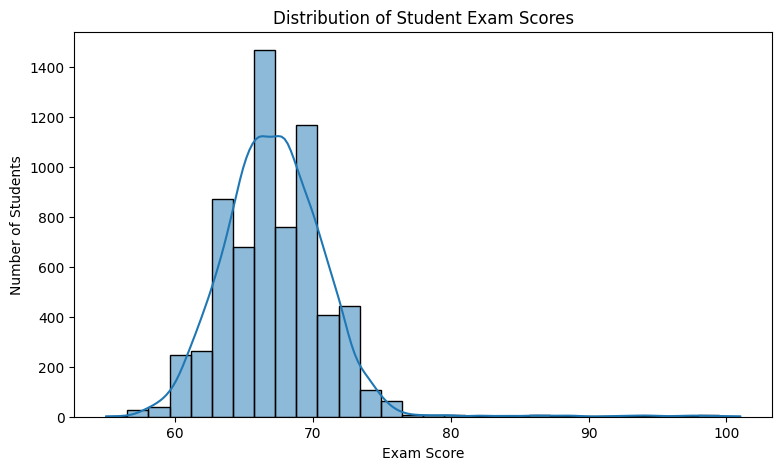

In [15]:

plt.figure(figsize=(9, 5))

sns.histplot(df['Exam_Score'], bins=30, kde=True)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()


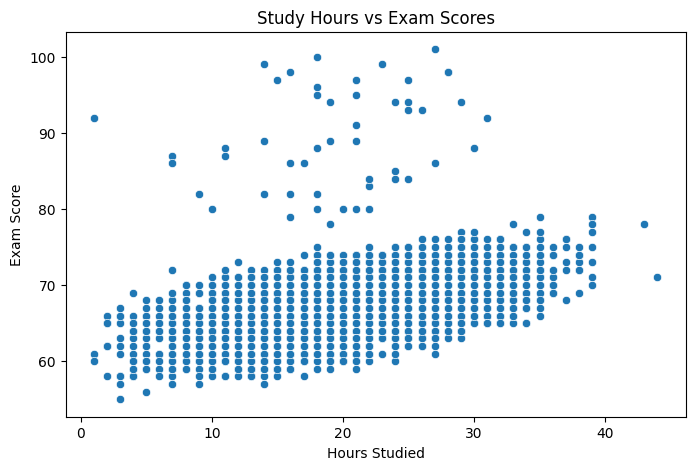

In [16]:

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Hours_Studied', y='Exam_Score')

plt.title("Study Hours vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")

plt.show()


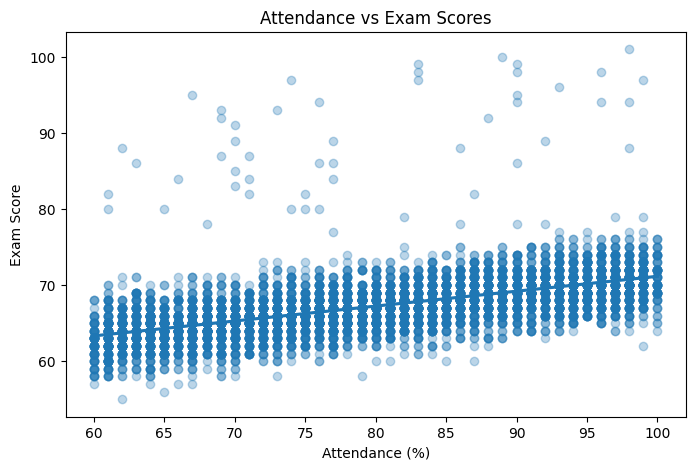

In [18]:

plt.figure(figsize=(8, 5))

sns.regplot(data=df, x='Attendance', y='Exam_Score',
            scatter_kws={'alpha': 0.3})

plt.title("Attendance vs Exam Scores")
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")

plt.show()


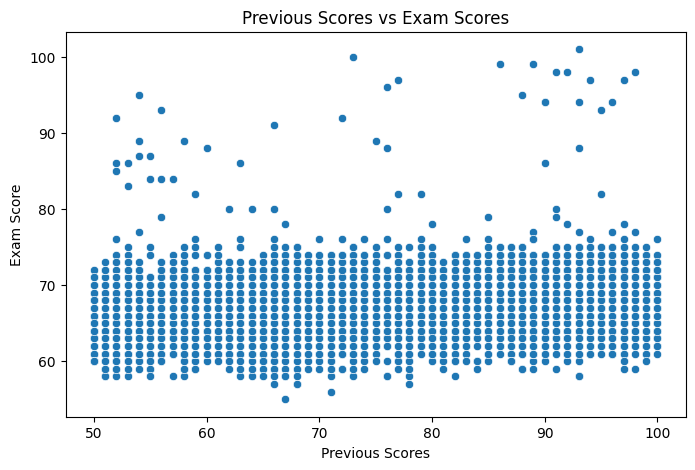

In [19]:

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Previous_Scores', y='Exam_Score')

plt.title("Previous Scores vs Exam Scores")
plt.xlabel("Previous Scores")
plt.ylabel("Exam Score")

plt.show()


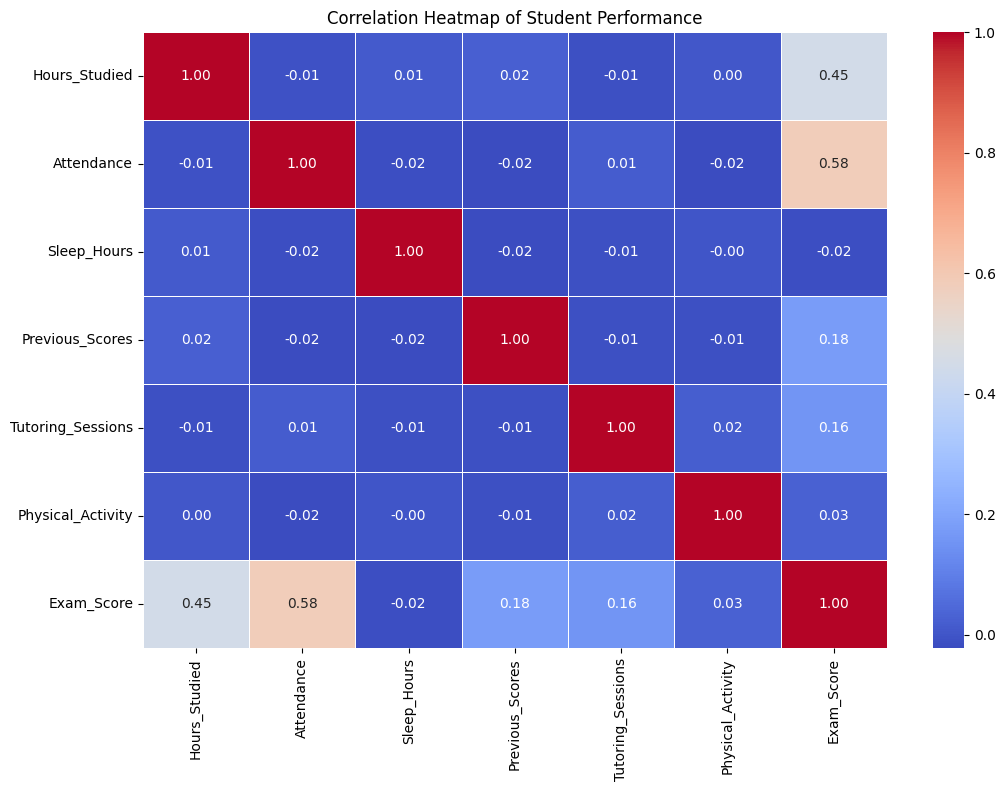

In [20]:

plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5)

plt.title("Correlation Heatmap of Student Performance")
plt.show()


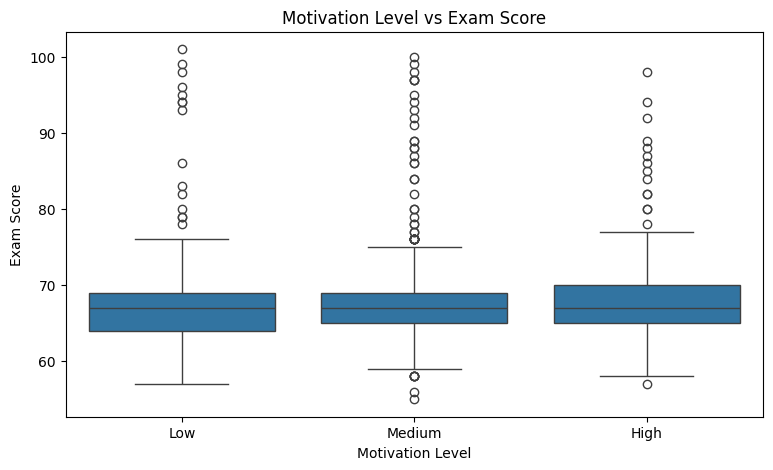

In [21]:

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='Motivation_Level', y='Exam_Score')

plt.title("Motivation Level vs Exam Score")
plt.xlabel("Motivation Level")
plt.ylabel("Exam Score")

plt.show()


In [22]:

# Data Cleaning

print("Before Cleaning:", df.shape)

df = df.drop_duplicates()

df = df.dropna(subset=['Exam_Score'])

print("After Cleaning:", df.shape)

print("\nMissing Values After Target Cleaning:")
print(df.isnull().sum().sum())


Before Cleaning: (6607, 20)
After Cleaning: (6607, 20)

Missing Values After Target Cleaning:
235


In [23]:

# Feature Selection

X = df.drop('Exam_Score', axis=1)
y = df['Exam_Score']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Variable: Exam_Score")


Features Shape: (6607, 19)
Target Shape: (6607,)

Target Variable: Exam_Score


In [24]:

# Identify numerical and categorical features

numerical_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(include='object').columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)


Numerical Features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Categorical Features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [25]:

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (5285, 19)
Testing Data: (1322, 19)


In [26]:

# Numerical preprocessing

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [27]:

# Define Machine Learning Models

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

print("Three ML algorithms selected successfully!")

for model_name in models:
    print(model_name)


Three ML algorithms selected successfully!
Linear Regression
Decision Tree
Random Forest


In [28]:

# Train Machine Learning Models

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")


Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [29]:

# Predict exam scores

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print(name, "prediction completed!")


Linear Regression prediction completed!
Decision Tree prediction completed!
Random Forest prediction completed!


In [30]:

# Evaluate all models

results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(results_df.round(3))


MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.452,3.256,1.804,0.770
1,Decision Tree,1.655,10.859,3.295,0.232
2,Random Forest,1.084,4.618,2.149,0.673


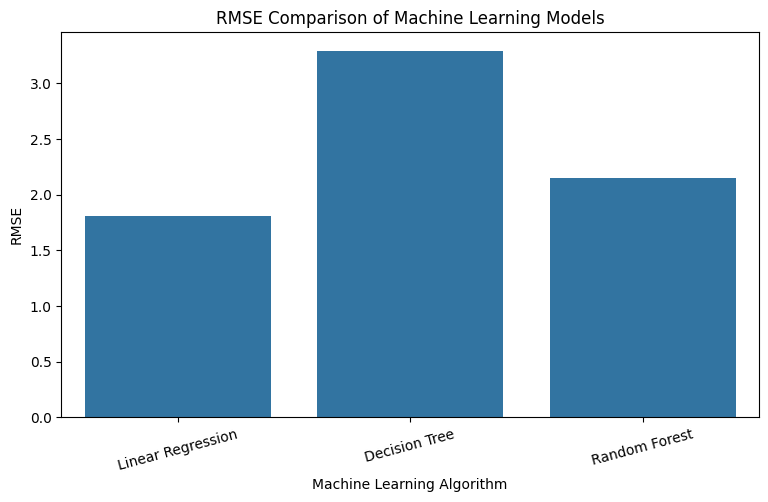

In [31]:

# Compare model performance

plt.figure(figsize=(9, 5))

sns.barplot(data=results_df, x='Model', y='RMSE')

plt.title("RMSE Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("RMSE")

plt.xticks(rotation=15)
plt.show()


In [32]:

# Select model with lowest RMSE

best_model_name = results_df.loc[
    results_df['RMSE'].idxmin(), 'Model'
]

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

print("Best Model RMSE:",
      results_df.loc[results_df['RMSE'].idxmin(), 'RMSE'])


Best Performing Model: Linear Regression
Best Model RMSE: 1.804444509272284


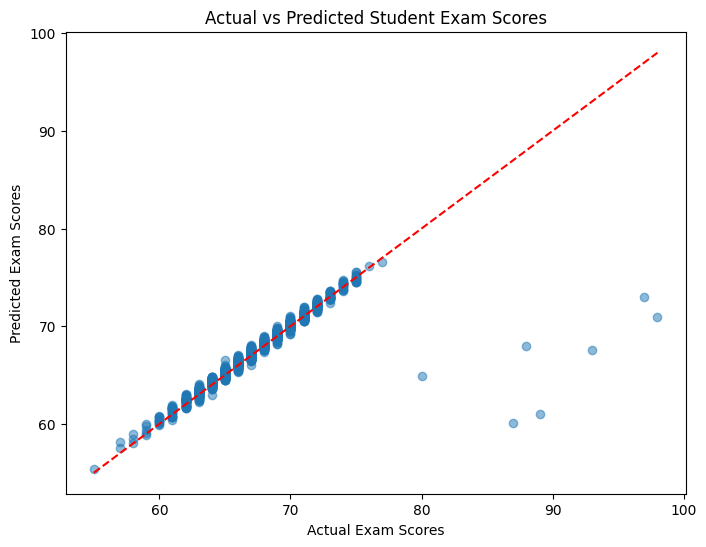

In [33]:

# Compare actual and predicted scores

best_predictions = predictions[best_model_name]

plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")

plt.title("Actual vs Predicted Student Exam Scores")

plt.show()


In [34]:

# Explain model predictions using permutation importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance.importances_mean
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Top 10 Important Features:")

display(importance_df.head(10))


Top 10 Important Features:


,Feature,Importance
1,Attendance,10.590754
0,Hours_Studied,6.454430
6,Previous_Scores,0.965764
3,Access_to_Resources,0.964210
2,Parental_Involvement,0.964202
9,Tutoring_Sessions,0.699204
10,Family_Income,0.329248
16,Parental_Education_Level,0.325517
7,Motivation_Level,0.317027
13,Peer_Influence,0.288025


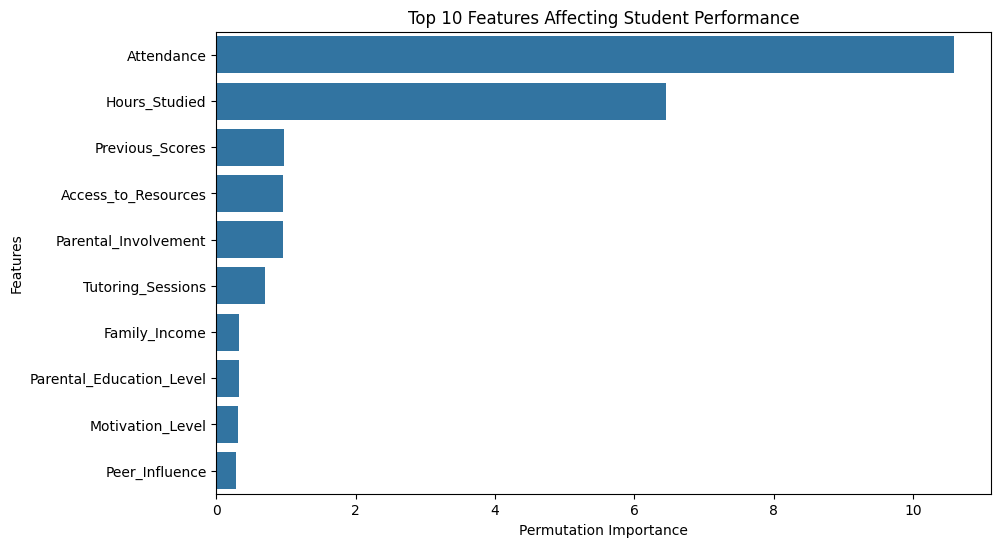

In [35]:

plt.figure(figsize=(10, 6))

top_features = importance_df.head(10)

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Features Affecting Student Performance")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")

plt.show()


In [36]:

# Academic Risk Classification

def classify_risk(score):

    if score < 50:
        return "High Risk"

    elif score < 70:
        return "Medium Risk"

    else:
        return "Low Risk"

print("Risk classification function created!")


Risk classification function created!


In [37]:

# Generate Early Warning Results

early_warning = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': best_predictions
})

early_warning['Risk Level'] = early_warning[
    'Predicted Score'
].apply(classify_risk)

print("Early Warning Results:")
display(early_warning.head(10))


Early Warning Results:


,Actual Score,Predicted Score,Risk Level
0,65,64.526283,Medium Risk
1,65,65.265114,Medium Risk
2,71,71.531263,Low Risk
3,64,64.277481,Medium Risk
4,66,66.521653,Medium Risk
5,66,66.612463,Medium Risk
6,72,72.470949,Low Risk
7,66,66.498269,Medium Risk
8,70,69.986045,Medium Risk
9,70,70.133271,Low Risk


Student Academic Risk Distribution:
Risk Level
Medium Risk    1016
Low Risk        306
Name: count, dtype: int64


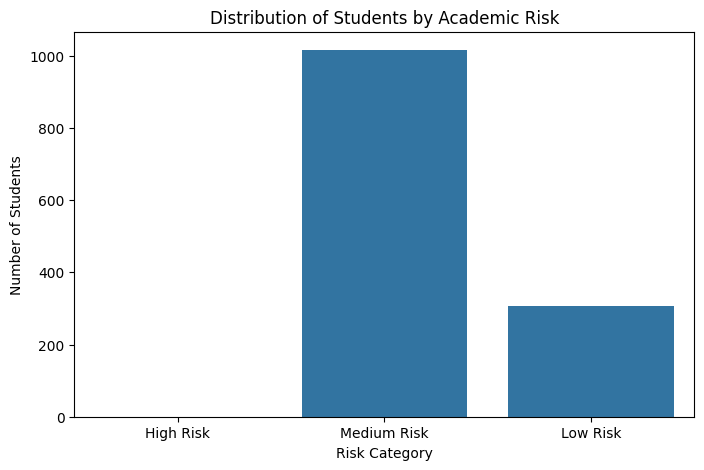

In [38]:

# Count students in each risk category

risk_counts = early_warning['Risk Level'].value_counts()

print("Student Academic Risk Distribution:")
print(risk_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=early_warning,
    x='Risk Level',
    order=['High Risk', 'Medium Risk', 'Low Risk']
)

plt.title("Distribution of Students by Academic Risk")
plt.xlabel("Risk Category")
plt.ylabel("Number of Students")

plt.show()


In [39]:

# Academic Improvement Recommendations

def recommend_action(risk):

    if risk == "High Risk":
        return "Immediate academic support and regular monitoring"

    elif risk == "Medium Risk":
        return "Improve study habits and monitor progress"

    else:
        return "Maintain current learning habits"

early_warning['Recommendation'] = early_warning[
    'Risk Level'
].apply(recommend_action)

display(early_warning.head(10))


,Actual Score,Predicted Score,Risk Level,Recommendation
0,65,64.526283,Medium Risk,Improve study habits and monitor progress
1,65,65.265114,Medium Risk,Improve study habits and monitor progress
2,71,71.531263,Low Risk,Maintain current learning habits
3,64,64.277481,Medium Risk,Improve study habits and monitor progress
4,66,66.521653,Medium Risk,Improve study habits and monitor progress
5,66,66.612463,Medium Risk,Improve study habits and monitor progress
6,72,72.470949,Low Risk,Maintain current learning habits
7,66,66.498269,Medium Risk,Improve study habits and monitor progress
8,70,69.986045,Medium Risk,Improve study habits and monitor progress
9,70,70.133271,Low Risk,Maintain current learning habits


In [40]:

# Save trained model

os.makedirs('/kaggle/working/models', exist_ok=True)
os.makedirs('/kaggle/working/results', exist_ok=True)

joblib.dump(
    best_model,
    '/kaggle/working/models/best_model.pkl'
)

results_df.to_csv(
    '/kaggle/working/results/model_comparison.csv',
    index=False
)

early_warning.to_csv(
    '/kaggle/working/results/early_warning_results.csv',
    index=False
)

importance_df.to_csv(
    '/kaggle/working/results/feature_importance.csv',
    index=False
)

print("Model and results saved successfully!")


Model and results saved successfully!


In [41]:

# Check saved project files

for root, dirs, files in os.walk('/kaggle/working'):
    for file in files:
        print(os.path.join(root, file))


/kaggle/working/models/best_model.pkl
/kaggle/working/results/early_warning_results.csv
/kaggle/working/results/feature_importance.csv
/kaggle/working/results/model_comparison.csv
/kaggle/working/.virtual_documents/__notebook_source__.ipynb


In [42]:

%%writefile /kaggle/working/app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Student Early Warning System",
    page_icon="🎓"
)

model = joblib.load("models/best_model.pkl")

st.title("🎓 Smart Student Academic Early Warning System")

st.write(
    "Predict student examination performance "
    "using Machine Learning."
)

st.header("Enter Student Information")

hours = st.number_input("Hours Studied", 0, 24, 5)
attendance = st.number_input("Attendance (%)", 0, 100, 80)
previous = st.number_input("Previous Scores", 0, 100, 60)
sleep = st.number_input("Sleep Hours", 0, 24, 7)
tutoring = st.number_input("Tutoring Sessions", 0, 20, 2)

if st.button("Predict Academic Performance"):

    student = pd.DataFrame([{
        'Hours_Studied': hours,
        'Attendance': attendance,
        'Previous_Scores': previous,
        'Sleep_Hours': sleep,
        'Tutoring_Sessions': tutoring
    }])

    st.error(
        "The complete dataset feature form must be added "
        "before running predictions."
    )


Writing /kaggle/working/app.py


In [43]:

# Create ZIP file for model and results

import shutil

shutil.make_archive(
    '/kaggle/working/Student_ML_Project',
    'zip',
    '/kaggle/working'
)

print("Project files packaged successfully!")


Project files packaged successfully!


In [44]:

# Cell 36: Save Complete Model Information

model_bundle = {
    'model': best_model,
    'feature_columns': X.columns.tolist(),
    'categorical_options': {
        col: sorted(X[col].dropna().unique().tolist())
        for col in categorical_features
    },
    'defaults': {
        col: (
            X[col].median()
            if col in numerical_features
            else X[col].mode()[0]
        )
        for col in X.columns
    }
}

joblib.dump(
    model_bundle,
    '/kaggle/working/models/student_model_bundle.pkl'
)

print("Complete model information saved successfully!")
print("Total input features:", len(X.columns))


Complete model information saved successfully!
Total input features: 19


In [45]:

# Verify saved model files

print("Saved Model Files:")

for file in os.listdir('/kaggle/working/models'):
    print(file)


Saved Model Files:
student_model_bundle.pkl
best_model.pkl


In [46]:

%%writefile /kaggle/working/app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Student Early Warning System",
    page_icon="🎓",
    layout="wide"
)

bundle = joblib.load("models/student_model_bundle.pkl")

model = bundle['model']
features = bundle['feature_columns']
options = bundle['categorical_options']
defaults = bundle['defaults']

st.title("🎓 Smart Student Academic Early Warning System")
st.write(
    "An Explainable Machine Learning application "
    "for predicting student academic performance."
)

st.divider()

st.subheader("Enter Student Information")

user_data = {}

with st.form("student_form"):

    for feature in features:

        default = defaults[feature]

        if feature in options:
            choices = options[feature]
            user_data[feature] = st.selectbox(
                feature,
                choices,
                index=choices.index(default)
                if default in choices else 0
            )

        else:
            user_data[feature] = st.number_input(
                feature,
                value=float(default)
            )

    submitted = st.form_submit_button(
        "Predict Academic Performance"
    )

if submitted:

    input_df = pd.DataFrame([user_data], columns=features)

    predicted_score = float(model.predict(input_df)[0])

    predicted_score = max(0, min(100, predicted_score))

    if predicted_score < 50:
        risk = "High Risk"
        recommendation = (
            "Provide immediate academic support "
            "and regular monitoring."
        )

    elif predicted_score < 70:
        risk = "Medium Risk"
        recommendation = (
            "Improve study habits and monitor progress."
        )

    else:
        risk = "Low Risk"
        recommendation = (
            "Maintain current learning habits."
        )

    st.divider()

    st.subheader("Prediction Results")

    col1, col2 = st.columns(2)

    col1.metric(
        "Predicted Exam Score",
        f"{predicted_score:.2f}"
    )

    col2.metric(
        "Academic Risk",
        risk
    )

    st.info(recommendation)

    st.caption(
        "This prediction is an estimate, not a confirmed "
        "academic outcome. Risk thresholds are illustrative."
    )

st.divider()

st.caption(
    "Developed as a Machine Learning academic mini-project."
)


Overwriting /kaggle/working/app.py
